# Quantum time stepping of the 1D Burgers equation with a block-encoded nonlinear term with no tensor networks

A Qiskit implementation of the nonlinear-term treatment from Siegl et al. (2026), tested on 1D Burgers with N = 8 grid points.

**Idea:** the nonlinear term needs diag(u), which changes every step. At each step we build a unitary that *block-encodes* diag(ψ), combine it with the linear part, and let a classical optimiser train the circuit for the next step.

**This version** builds that unitary as a dense matrix from the exact statevector.Tensor networks are applied in "experiments/run_simulation_tn.py". Circuits are simulated exactly (no noise).

Run all cells top to bottom.

## 1. Setup
All sizes follow from `N`. Qubit order: control, LCU qubit, data qubits, ancilla A1, ancilla A2 (Qiskit is little-endian).

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

In [44]:
N = 8
nu = 0.1
L_dom = 1.0
T = 1.0
SHOTS = None  # None = exact expectation values

assert N >= 4 and N & (N - 1) == 0, "N must be a power of 2"

n_data = int(np.log2(N))
n_total = n_data + 4
dim_total = 2 ** n_total

# qubits: 0 control | 1 LCU | 2.. data | A1 ancilla of U_L, U_C | A2 ancilla of U_phi
C, Lq = 0, 1
DATA = list(range(2, 2 + n_data))
A1, A2 = 2 + n_data, 3 + n_data

x = np.linspace(0, L_dom, N)
dx = x[1] - x[0]
u_max = 1.0
# stable explicit Euler; n_steps is a multiple of 4 so t = 0.25, 0.5, 0.75, 1.0 are whole steps
dt_max = 0.4 * min(dx ** 2 / nu, dx / u_max)
n_steps = 4 * int(np.ceil(T / (4 * dt_max)))
dt = T / n_steps

n_layers = max(5, int(np.ceil(N / n_data)))

print(f"N={N}  data qubits={n_data}  total qubits={n_total}  dt={dt:.5f}  steps={n_steps}  layers={n_layers}")
print(f"nu*dt/dx^2 = {nu * dt / dx ** 2:.3f}   u_max*dt/dx = {u_max * dt / dx:.3f}")

N=8  data qubits=3  total qubits=7  dt=0.05000  steps=20  layers=5
nu*dt/dx^2 = 0.245   u_max*dt/dx = 0.350


## 2. Classical reference
Explicit Euler solved classically; used as ground truth.

In [45]:
u = np.sin(np.pi * x)
u[0] = u[-1] = 0.0

D1 = np.zeros((N, N))
D2 = np.zeros((N, N))
for i in range(1, N - 1):
    D1[i, i - 1], D1[i, i + 1] = -1 / (2 * dx), 1 / (2 * dx)
    D2[i, i - 1], D2[i, i], D2[i, i + 1] = 1 / dx ** 2, -2 / dx ** 2, 1 / dx ** 2

classical_solution = [u.copy()]
for _ in range(n_steps):
    u = u + dt * (nu * (D2 @ u) - u * (D1 @ u))
    u[0] = u[-1] = 0.0
    classical_solution.append(u.copy())
classical_solution = np.array(classical_solution)

## 3. Ansatz
RY and CX layers store the normalised field ψ = u/‖u‖ in the amplitudes of 3 qubits. The norm ‖u‖ is tracked as a classical number.

In [46]:
theta = ParameterVector("θ", n_data * (n_layers + 1))
qc = QuantumCircuit(n_data)
p = 0
for layer in range(n_layers + 1):
    for q in range(n_data):
        qc.ry(theta[p], q)
        p += 1
    if layer < n_layers:
        for q in range(n_data - 1):
            qc.cx(q, q + 1)

## 4. Fit the initial state
A classical optimiser finds the angles θ₀ that prepare ψ at t = 0. The overlap should be 1.

In [47]:
u_initial = classical_solution[0]
norm_j = np.linalg.norm(u_initial)
u_target = u_initial / norm_j


# signed overlap, so the sign of ψ is correct
def fit_cost(params):
    sv = Statevector(qc.assign_parameters({theta: params})).data.real
    return 1.0 - u_target @ sv


best = None
for seed in range(10):
    start = np.random.default_rng(seed).uniform(0, 2 * np.pi, qc.num_parameters)
    attempt = minimize(fit_cost, start, method="L-BFGS-B", options={"ftol": 1e-15, "gtol": 1e-12, "maxiter": 2000})
    if best is None or attempt.fun < best.fun:
        best = attempt
    if best.fun < 1e-9:
        break

theta_j = best.x
sv_init = Statevector(qc.assign_parameters({theta: theta_j})).data.real
print("initial-state overlap:", u_target @ sv_init)

initial-state overlap: 0.9999999999999994


## 5. Block encodings
Each operator M is placed, divided by a constant c, in the top-left block of a unitary; post-selecting the ancilla on |0⟩ then applies M/c.

* `U_L`: linear part (identity + diffusion). `U_C`: derivative part (holds the minus sign). Both are fixed.
* `U_phi`: the field diag(ψ). It changes every step. Its constant is c = max|ψ|, which does not grow with N: this is the key point of the paper.

In [48]:
def matrix_sqrt_psd(H):
    eigvals, eigvecs = np.linalg.eigh((H + H.conj().T) / 2)
    return (eigvecs * np.sqrt(np.clip(eigvals, 0, None))) @ eigvecs.conj().T


# unitary with M/c in the top-left block (ancilla = most significant qubit)
def block_encode(M, label):
    n = M.shape[0]
    c = np.linalg.norm(M, 2) * (1 + 1e-6)
    A = M / c
    I = np.eye(n)

    U = np.block([[A, matrix_sqrt_psd(I - A @ A.conj().T)],
                  [matrix_sqrt_psd(I - A.conj().T @ A), -A.conj().T]])

    assert np.allclose(U.conj().T @ U, np.eye(2 * n), atol=1e-9), "U is not unitary"
    assert np.allclose(c * U[:n, :n], M), "top-left block is not M"
    return UnitaryGate(U, label=label), c


O_L = np.eye(N) + dt * nu * D2
O_C = -dt * D1

# U_phi is built from the exact statevector (the shortcut)
U_L, c_L = block_encode(O_L, "U_L")
U_C, c_C = block_encode(O_C, "U_C")
U_phi, c_D = block_encode(np.diag(sv_init), "U_phi")

## 6. One time step
The linear and nonlinear parts are combined into one circuit. A Hadamard test then measures ⟨σ_z⟩ of the control qubit; training the next angles θ′ pushes it to 1. The trained φ also gives the success probability α and the new norm.

**6.1 Weights and masks**

In [49]:
beta1 = c_L
beta2 = c_C * c_D * norm_j
beta_full = beta1 + beta2
omega = 2 * np.arccos(np.sqrt(beta2 / beta_full))
# classical operator, used only for checks
O_full = O_L - dt * norm_j * np.diag(sv_init) @ D1

theta_p = ParameterVector("θ'", qc.num_parameters)
phi_p = Parameter("φ")

# post-selection masks: L = A1 = A2 = 0
idx = np.arange(dim_total)
keep = (((idx >> Lq) & 1) == 0) & (((idx >> A1) & 1) == 0) & (((idx >> A2) & 1) == 0)
cbit = (idx >> C) & 1
branch1_idx = (1 << C) + (np.arange(N) << DATA[0])
assert keep[branch1_idx].all() and (cbit[branch1_idx] == 1).all()

rng = np.random.default_rng(0)

**6.2 Circuit builders**
`0b11` means control = 1 and LCU = 1 (linear branch); `0b01` means control = 1 and LCU = 0 (nonlinear branch).

In [50]:
def ansatz_gate(params, label, inverse=False):
    circuit = qc.assign_parameters(dict(zip(theta, params)))
    return (circuit.inverse() if inverse else circuit).to_gate(label=label)


def build_suffix(th_next, phi):
    s = QuantumCircuit(n_total)
    s.append(ansatz_gate(th_next, "U†(θ_j+1)", inverse=True).control(1), [C] + DATA)
    s.ry(-phi, C)
    return s


def build_step(th_j, th_next=None, phi=None):
    c = QuantumCircuit(n_total)
    c.h(C)
    c.cry(omega, C, Lq)
    c.append(ansatz_gate(th_j, "U(θ_j)").control(1), [C] + DATA)
    c.append(U_L.control(2, ctrl_state=0b11), [C, Lq] + DATA + [A1])  # linear branch
    c.append(U_C.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A1])  # nonlinear branch: derivative
    c.append(U_phi.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A2])  # nonlinear branch: field
    c.cry(-omega, C, Lq)
    if th_next is not None:
        c.compose(build_suffix(th_next, phi), inplace=True)
    return c

**6.3 Check**
Before any training, the circuit must equal the classical operator. If this passes, the qubit order and signs are right.

In [51]:
def z_from_probabilities(pr):
    n0 = pr[keep & (cbit == 0)].sum()
    n1 = pr[keep & (cbit == 1)].sum()
    return (n0 - n1) / (n0 + n1)


sv_pre = Statevector(build_step(theta_j))
w_chk = sv_pre.data[branch1_idx]
assert np.allclose(w_chk, O_full @ sv_init / (beta_full * np.sqrt(2)), atol=1e-8), "circuit != O_full psi / beta"
print("circuit reproduces O_full|psi>/beta_full  ✔")

circuit reproduces O_full|psi>/beta_full  ✔


**6.4 Train the next step**
θ′ and φ are trained together to maximise ⟨σ_z⟩. The cost should reach about 0.

In [52]:
suffix_template = build_suffix(theta_p, phi_p)


def measure_sigma_z(params, shots=None):
    th, phi = params[:-1], params[-1]
    bound = suffix_template.assign_parameters({**dict(zip(theta_p, th)), phi_p: phi})
    pr = sv_pre.evolve(bound).probabilities()
    if shots is None:
        return z_from_probabilities(pr)
    out = rng.choice(dim_total, size=shots, p=pr)
    ok = keep[out]
    n0 = np.sum(ok & (cbit[out] == 0))
    n1 = np.sum(ok & (cbit[out] == 1))
    return 0.0 if n0 + n1 == 0 else (n0 - n1) / (n0 + n1)


def cost(params, shots=None):
    return 1.0 - measure_sigma_z(params, shots)


alpha0 = 2 * sv_pre.probabilities()[keep & (cbit == 1)].sum()
phi0 = 2 * np.arctan(np.sqrt(alpha0))

res = minimize(cost, np.append(theta_j, phi0), method="L-BFGS-B",
               options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-9})
theta_next, phi_opt = res.x[:-1], res.x[-1]
ez = measure_sigma_z(res.x)
print(f"cost 1-<Z> = {res.fun:.3e}   <Z> = {ez:.6f}")

ez_full = z_from_probabilities(Statevector(build_step(theta_j, theta_next, phi_opt)).probabilities())
print(f"<Z> full circuit = {ez_full:.6f}   (suffix evolution {ez:.6f})")

cost 1-<Z> = 1.255e-14   <Z> = 1.000000
<Z> full circuit = 1.000000   (suffix evolution 1.000000)


**6.5 Success probability, norm and fidelity**
All three come from the trained φ and the measured ⟨σ_z⟩ (paper Eq. 4 and 5). The classical values are printed only for comparison.

In [53]:
def normalization_factor(alpha, phi):
    return (1 + alpha) / (2 * np.sin(phi) - (np.sqrt(alpha) - 1 / np.sqrt(alpha)) * np.cos(phi))


def fidelity_eq4(ez, alpha, phi):
    return (alpha * (ez + np.cos(phi)) + ez - np.cos(phi)) ** 2 / (4 * alpha * np.sin(phi) ** 2)


alpha_succ = np.tan(phi_opt / 2) ** 2
f_O = normalization_factor(alpha_succ, phi_opt)
F_eq4 = fidelity_eq4(ez, alpha_succ, phi_opt)
norm_j1 = beta_full * f_O * norm_j

psi_next = Statevector(qc.assign_parameters({theta: theta_next})).data.real
psi_exact = O_full @ sv_init
alpha_exact = np.linalg.norm(psi_exact) ** 2 / beta_full ** 2
psi_exact /= np.linalg.norm(psi_exact)
print(f"alpha from phi = {alpha_succ:.5f}   exact alpha = {alpha_exact:.5f}")
print(f"F (Eq.4, no classical data) = {F_eq4:.6f}   true fidelity = {(psi_next @ psi_exact) ** 2:.6f}")
print(f"norm_j1 from Eq.5 = {norm_j1:.6f}   classical = {np.linalg.norm(classical_solution[1]):.6f}")

alpha from phi = 0.48724   exact alpha = 0.48724
F (Eq.4, no classical data) = 1.000000   true fidelity = 1.000000
norm_j1 from Eq.5 = 1.785705   classical = 1.785705


**6.6 First step vs classical**

max |u_quantum - u_classical| = 2.0037353953838988e-07


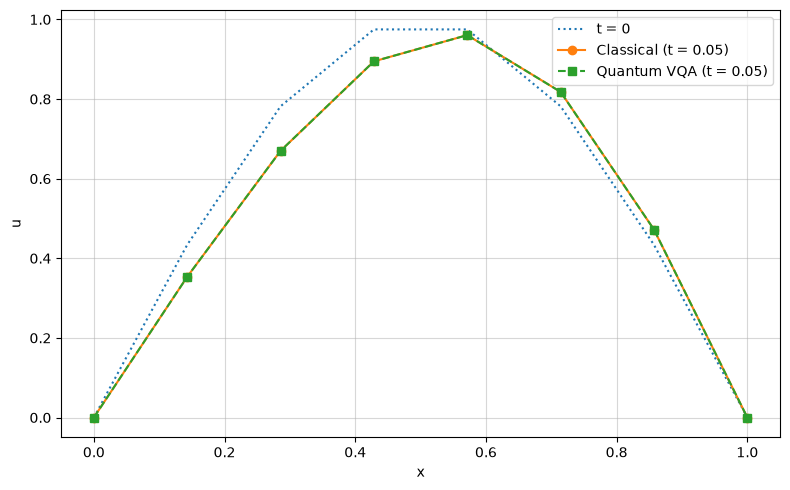

In [54]:
u_quantum = norm_j1 * psi_next
plt.figure(figsize=(8, 5))
plt.plot(x, classical_solution[0], ":", label="t = 0")
plt.plot(x, classical_solution[1], "o-", label=f"Classical (t = {dt:.3g})")
plt.plot(x, u_quantum, "s--", label=f"Quantum VQA (t = {dt:.3g})")
plt.xlabel("x"); plt.ylabel("u"); plt.grid(alpha=0.5); plt.legend(); plt.tight_layout()

print("max |u_quantum - u_classical| =", np.max(np.abs(u_quantum - classical_solution[1])))

## 7. The complete circuit
One full time step, saved as `full_circuit.png`.

![complete circuit](full_circuit.png)

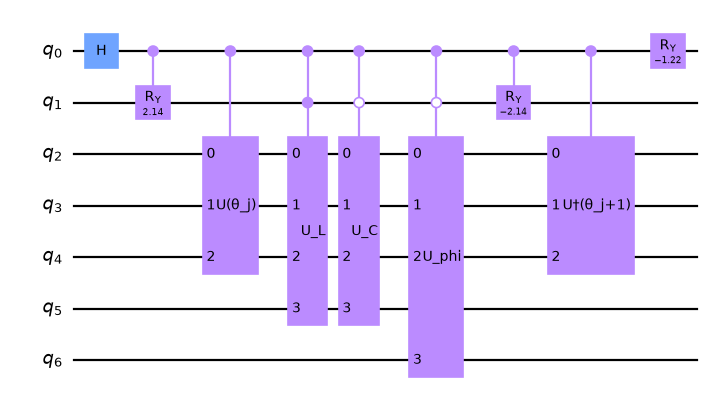

In [55]:
full_circuit = build_step(theta_j, theta_next, phi_opt)
full_circuit.draw("mpl", style="clifford", scale=0.8, fold=-1)

## 8. Time evolution
The step from section 6 is repeated 20 times; `U_phi` is rebuilt from the new field each time. Expected: ⟨Z⟩ = 1, α equal to the exact value, error around 1e-7.

In [56]:
def ansatz_state(params):
    return Statevector(qc.assign_parameters({theta: params})).data.real


def rel_l2_error(approx, reference):
    return np.linalg.norm(approx - reference) / np.linalg.norm(reference)


def build_prefix(th_j, U_phi_j, omega_j):
    c = QuantumCircuit(n_total)
    c.h(C)
    c.append(ansatz_gate(th_j, "U(θ_j)").control(1), [C] + DATA)
    c.cry(omega_j, C, Lq)
    c.append(U_L.control(2, ctrl_state=0b11), [C, Lq] + DATA + [A1])
    c.append(U_C.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A1])
    c.append(U_phi_j.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A2])
    c.cry(-omega_j, C, Lq)
    return c


def sigma_z_of(params, sv_prefix, shots=None):
    th, phi = params[:-1], params[-1]
    bound = suffix_template.assign_parameters({**dict(zip(theta_p, th)), phi_p: phi})
    pr = sv_prefix.evolve(bound).probabilities()
    if shots is None:
        return z_from_probabilities(pr)
    out = rng.choice(dim_total, size=shots, p=pr)
    ok = keep[out]
    n0 = np.sum(ok & (cbit[out] == 0))
    n1 = np.sum(ok & (cbit[out] == 1))
    return 0.0 if n0 + n1 == 0 else (n0 - n1) / (n0 + n1)


def train_next_step(x0, sv_prefix, shots):
    def cost_fn(params):
        return 1.0 - sigma_z_of(params, sv_prefix, shots)

    if shots is None:
        return minimize(cost_fn, x0, method="L-BFGS-B",
                        options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-9})
    return minimize(cost_fn, x0, method="COBYLA",
                    options={"maxiter": 2000, "rhobeg": 0.1})

In [57]:
# one full time step: encode, build circuit, check, train, update norm
def quantum_step(th_j, norm_cur, shots=None, check=True):
    psi_j = ansatz_state(th_j)
    U_phi_j, c_D_j = block_encode(np.diag(psi_j), "U_phi")
    beta2_j = c_C * c_D_j * norm_cur
    beta_full_j = c_L + beta2_j
    omega_j = 2 * np.arccos(np.sqrt(beta2_j / beta_full_j))

    O_full_j = O_L - dt * norm_cur * np.diag(psi_j) @ D1
    sv_prefix = Statevector(build_prefix(th_j, U_phi_j, omega_j))
    if check:
        w_j = sv_prefix.data[branch1_idx]
        assert np.allclose(w_j, O_full_j @ psi_j / (beta_full_j * np.sqrt(2)), atol=1e-7), \
            "circuit != O_full psi / beta"

    alpha0_j = 2 * sv_prefix.probabilities()[keep & (cbit == 1)].sum()
    x0 = np.append(th_j, 2 * np.arctan(np.sqrt(alpha0_j)))
    result = train_next_step(x0, sv_prefix, shots)
    th_next, phi_j = result.x[:-1], result.x[-1]
    ez_j = sigma_z_of(result.x, sv_prefix, shots)

    alpha_j = np.tan(phi_j / 2) ** 2
    norm_next = beta_full_j * normalization_factor(alpha_j, phi_j) * norm_cur

    psi_exact_j = O_full_j @ psi_j
    alpha_exact_j = np.linalg.norm(psi_exact_j) ** 2 / beta_full_j ** 2
    psi_exact_j /= np.linalg.norm(psi_exact_j)

    info = dict(ez=ez_j,
                alpha=alpha_j,
                alpha_exact=alpha_exact_j,
                F_eq4=fidelity_eq4(ez_j, alpha_j, phi_j),
                F_true=(ansatz_state(th_next) @ psi_exact_j) ** 2,
                beta_full=beta_full_j)
    return th_next, norm_next, info

In [58]:
theta_cur, norm_cur = theta_j.copy(), norm_j
u_quantum_hist = [norm_cur * sv_init]
infos = []

for j in range(n_steps):
    theta_cur, norm_cur, info = quantum_step(theta_cur, norm_cur, shots=SHOTS)
    u_quantum_hist.append(norm_cur * ansatz_state(theta_cur))
    infos.append(info)
    err = rel_l2_error(u_quantum_hist[-1], classical_solution[j + 1])
    print(f"step {j+1:3d}  t={dt*(j+1):.3f}  <Z>={info['ez']:.5f}  alpha(φ)={info['alpha']:.4f} "
          f"(exact {info['alpha_exact']:.4f})  F_eq4={info['F_eq4']:.5f}  F_true={info['F_true']:.5f}  "
          f"rel.L2 err={err:.2e}")

u_quantum_hist = np.array(u_quantum_hist)

step   1  t=0.050  <Z>=1.00000  alpha(φ)=0.4872 (exact 0.4872)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.04e-07
step   2  t=0.100  <Z>=1.00000  alpha(φ)=0.4899 (exact 0.4899)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.09e-07
step   3  t=0.150  <Z>=1.00000  alpha(φ)=0.4971 (exact 0.4971)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=7.08e-08
step   4  t=0.200  <Z>=1.00000  alpha(φ)=0.5074 (exact 0.5074)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=7.99e-08
step   5  t=0.250  <Z>=1.00000  alpha(φ)=0.5168 (exact 0.5168)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.21e-07
step   6  t=0.300  <Z>=1.00000  alpha(φ)=0.5218 (exact 0.5218)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.53e-07
step   7  t=0.350  <Z>=1.00000  alpha(φ)=0.5291 (exact 0.5291)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.75e-07
step   8  t=0.400  <Z>=1.00000  alpha(φ)=0.5379 (exact 0.5379)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=5.48e-07
step   9  t=0.450  <Z>=1.00000  alpha(φ)=0.5477 (exact 0.5477)  F_eq4=1.00000  F

**Classical vs quantum at t = 0.25, 0.5, 0.75, 1.0**

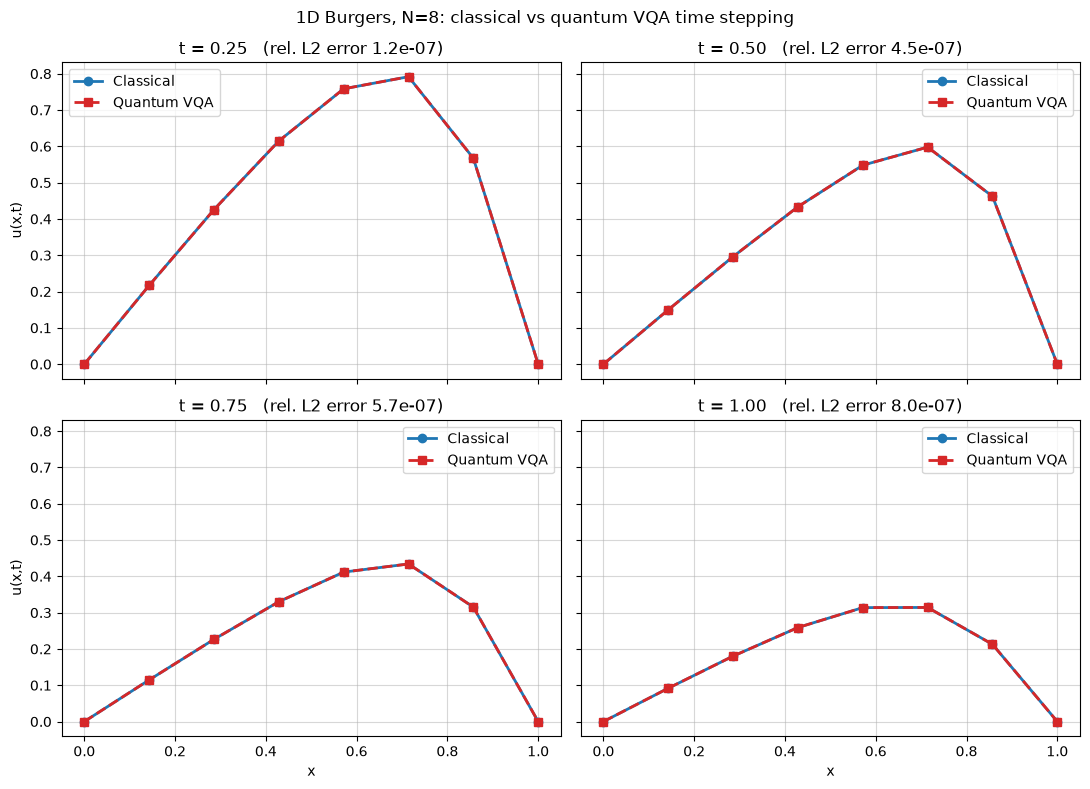

In [59]:
times_to_plot = T * np.array([0.25, 0.5, 0.75, 1.0])
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), times_to_plot):
    k = int(round(t / dt))
    ax.plot(x, classical_solution[k], "o-", color="#1f77b4", lw=2, label="Classical")
    ax.plot(x, u_quantum_hist[k], "s--", color="#d62728", lw=2, label="Quantum VQA")
    ax.set_title(f"t = {t:.2f}   (rel. L2 error {rel_l2_error(u_quantum_hist[k], classical_solution[k]):.1e})")
    ax.grid(alpha=0.5)
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("u(x,t)")
plt.suptitle(f"1D Burgers, N={N}: classical vs quantum VQA time stepping")
plt.tight_layout()

plt.show()

**Error and success probability over time**

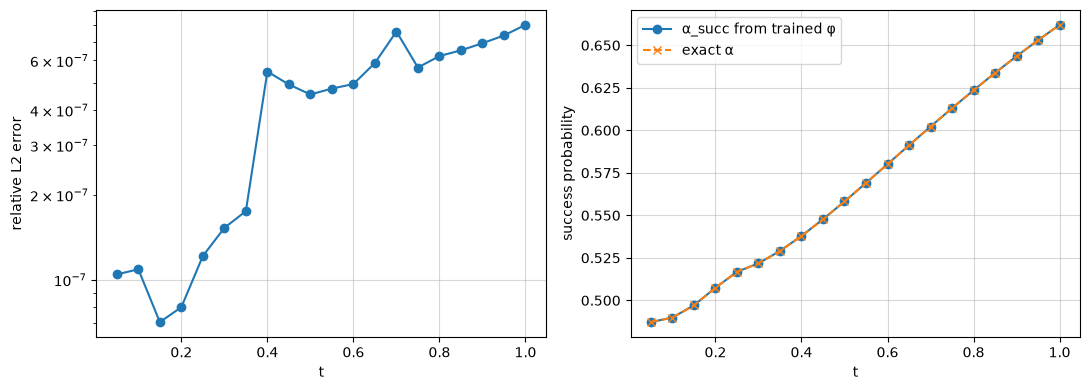

In [60]:
steps = np.arange(1, n_steps + 1)
rel_err = [rel_l2_error(u_quantum_hist[k], classical_solution[k]) for k in steps]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(dt * steps, rel_err, "o-")
ax[0].set_xlabel("t"); ax[0].set_ylabel("relative L2 error"); ax[0].grid(alpha=0.5)
ax[1].plot(dt * steps, [i["alpha"] for i in infos], "o-", label="α_succ from trained φ")
ax[1].plot(dt * steps, [i["alpha_exact"] for i in infos], "x--", label="exact α")
ax[1].set_xlabel("t"); ax[1].set_ylabel("success probability"); ax[1].grid(alpha=0.5); ax[1].legend()
plt.tight_layout()

plt.show()

## 9. Main claim of the paper: success probability vs N
The state-based encoding divides by ‖φ‖₂ (grows like √N), the block-diagonal one by max|φ| (does not grow). The plot shows this from the formulas, without circuits: dashed lines (state-based) fall like 1/N, solid lines (block-diagonal) stay roughly flat. A narrow peak is the exception where both stay flat.

In [61]:
def alphas(phi):
    s2 = np.sum(phi ** 2)
    s4 = np.sum(phi ** 4)
    alpha_state = s4 / s2 ** 2
    alpha_block = s4 / (s2 * np.max(phi ** 2))
    return alpha_state, alpha_block


def field(kind, n_grid, generator):
    xs = np.linspace(0, 1, n_grid)
    if kind == "uniform":
        return np.ones(n_grid)
    if kind == "uniform random":
        return generator.uniform(0, 1, n_grid)
    if kind == "gaussian random":
        return generator.standard_normal(n_grid)
    if kind == "sin(pi x)":
        return np.sin(np.pi * xs)
    if kind == "shock":
        return -np.tanh((xs - 0.5) / 0.02)
    if kind == "narrow peak":
        grid_index = np.arange(n_grid)
        return np.exp(-((grid_index - n_grid // 2) / 2.0) ** 2)
    raise ValueError(kind)

In [62]:
kinds = ["uniform", "uniform random", "gaussian random", "sin(pi x)", "shock", "narrow peak"]
qubits = np.arange(3, 21)
sizes = 2 ** qubits
n_trials = 20
rng_alpha = np.random.default_rng(0)

results = {}
for kind in kinds:
    state_vals, block_vals = [], []
    for n_grid in sizes:
        trials = n_trials if "random" in kind else 1
        a = np.array([alphas(field(kind, n_grid, rng_alpha)) for _ in range(trials)])
        state_vals.append(a[:, 0].mean())
        block_vals.append(a[:, 1].mean())
    results[kind] = (np.array(state_vals), np.array(block_vals))

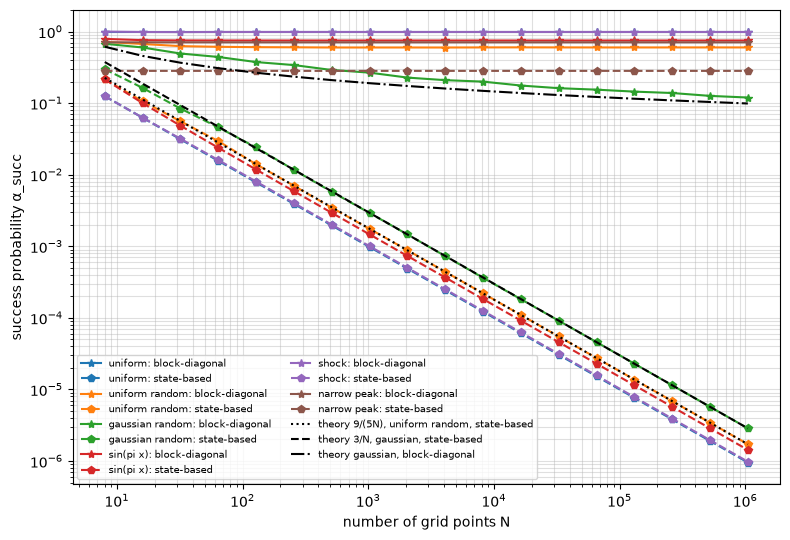

In [63]:
colors = dict(zip(kinds, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(8, 5.5))
for kind in kinds:
    ax.loglog(sizes, results[kind][1], "*-", color=colors[kind], label=f"{kind}: block-diagonal")
    ax.loglog(sizes, results[kind][0], "p--", color=colors[kind], label=f"{kind}: state-based")
ax.loglog(sizes, 9 / (5 * sizes), "k:", label="theory 9/(5N), uniform random, state-based")
ax.loglog(sizes, 3 / sizes, "k--", label="theory 3/N, gaussian, state-based")
ax.loglog(sizes, 3 / (2 * qubits * np.log(2) + np.log(qubits * np.log(2))), "k-.", label="theory gaussian, block-diagonal")
ax.set_xlabel("number of grid points N")
ax.set_ylabel("success probability α_succ")
ax.grid(alpha=0.4, which="both")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 10. Summary
**Results (N = 8, 20 steps):** the circuit matches the classical operator at every step, ⟨σ_z⟩ = 1, α from φ equals the exact α, and the relative error stays between 1e-7 and 8e-7.

**Limitations:** `U_phi` is a dense matrix, so only small N runs; circuits are simulated exactly; the ansatz can represent the state exactly at N = 8; no quantum speedup is claimed.

**Next:** the experiments/run_simulation_tn.py replaces the dense `U_phi`.